In [1]:

# STEP 1: Install and import the dataset

!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd

# Download dataset
dataset = fetch_ucirepo(id=601)

# Separate input data and output
X = dataset.data.features
y = dataset.data.targets

# Display first five records
print("Machine operating data:")
display(X.head())

print("Failure information:")
display(y.head())

print("Dataset shape:", X.shape)
print("Failure distribution:")
print(y["Machine failure"].value_counts())


Machine operating data:


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


Failure information:


,Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,0,0,0,0,0
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0


Dataset shape: (10000, 6)
Failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [2]:

# STEP 2: Data preparation

# Combine features and target
df = X.copy()
df["Machine failure"] = y["Machine failure"]

# Convert machine type into numerical values
df = pd.get_dummies(df, columns=["Type"], drop_first=True, dtype=int)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Display prepared data
display(df.head())

print("Final dataset shape:", df.shape)


Missing values:
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
Type_L                 0
Type_M                 0
dtype: int64


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,1,0
2,298.1,308.5,1498,49.4,5,0,1,0
3,298.2,308.6,1433,39.5,7,0,1,0
4,298.2,308.7,1408,40.0,9,0,1,0


Final dataset shape: (10000, 8)


In [3]:

from sklearn.model_selection import train_test_split

X_data = df.drop("Machine failure", axis=1)
y_data = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_data,
    test_size=0.2,
    random_state=42,
    stratify=y_data
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training failures:", y_train.sum())
print("Testing failures:", y_test.sum())



Training records: 8000
Testing records: 2000
Training failures: 271
Testing failures: 68


In [4]:

# STEP 4: Train the Machine Learning model

from sklearn.ensemble import RandomForestClassifier

# Create model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train model
model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")


Machine Learning model trained successfully!


In [5]:

# STEP 5: Evaluate the trained model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 98.1 %

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.94      0.47      0.63        68

    accuracy                           0.98      2000
   macro avg       0.96      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000


Confusion Matrix:
[[1930    2]
 [  36   32]]


In [6]:

# STEP 6: Predict machine failure

# Example machine operating conditions
new_machine = pd.DataFrame([{
    "Air temperature": 300.0,
    "Process temperature": 310.0,
    "Rotational speed": 1400,
    "Torque": 50.0,
    "Tool wear": 200,
    "Type_L": 1,
    "Type_M": 0
}])

# Predict
prediction = model.predict(new_machine)[0]
probability = model.predict_proba(new_machine)[0][1]

print("Machine failure prediction:")

if prediction == 1:
    print("WARNING: Potential machine failure detected!")
else:
    print("Machine appears healthy.")

print("Estimated failure probability:",
      round(probability * 100, 2), "%")


Machine failure prediction:
Machine appears healthy.
Estimated failure probability: 2.0 %


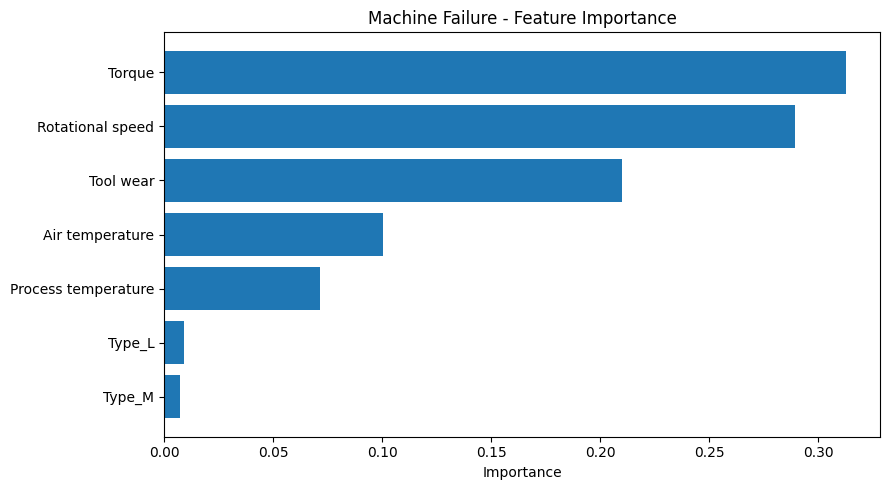

,Feature,Importance
3,Torque,0.312612
2,Rotational speed,0.289263
4,Tool wear,0.209803
0,Air temperature,0.100226
1,Process temperature,0.071705
5,Type_L,0.009284
6,Type_M,0.007107


In [7]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=True
)

# Visualize
plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Machine Failure - Feature Importance")
plt.tight_layout()
plt.show()

display(importance.sort_values(
    by="Importance", ascending=False
))


In [8]:

# STEP 7: Improve failure detection

from sklearn.metrics import classification_report

# Get failure probabilities
failure_probabilities = model.predict_proba(X_test)[:, 1]

# Use a lower threshold
threshold = 0.30

# Generate new predictions
improved_predictions = (
    failure_probabilities >= threshold
).astype(int)

print("Results with 0.30 threshold:")
print(classification_report(
    y_test,
    improved_predictions,
    zero_division=0
))


Results with 0.30 threshold:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.79      0.71      0.74        68

    accuracy                           0.98      2000
   macro avg       0.89      0.85      0.87      2000
weighted avg       0.98      0.98      0.98      2000



In [9]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Compare both thresholds
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],

    "Threshold 0.50": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],

    "Threshold 0.30": [
        accuracy_score(y_test, improved_predictions),
        precision_score(y_test, improved_predictions),
        recall_score(y_test, improved_predictions),
        f1_score(y_test, improved_predictions)
    ]
})

display(comparison.round(3))


,Metric,Threshold 0.50,Threshold 0.30
0,Accuracy,0.981,0.984
1,Precision,0.941,0.787
2,Recall,0.471,0.706
3,F1 Score,0.627,0.744


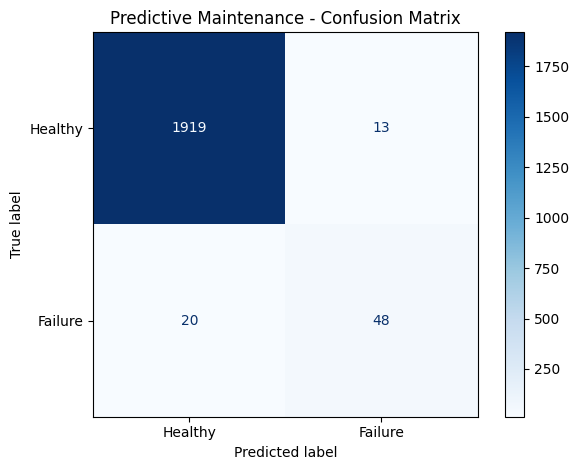

In [10]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion matrix at selected threshold
ConfusionMatrixDisplay.from_predictions(
    y_test,
    improved_predictions,
    display_labels=["Healthy", "Failure"],
    cmap="Blues"
)

plt.title("Predictive Maintenance - Confusion Matrix")
plt.tight_layout()
plt.show()


In [11]:

import joblib

# Save trained model
joblib.dump(model, "predictive_maintenance_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [12]:

from google.colab import files

files.download("predictive_maintenance_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

# Save project outputs

comparison.to_csv("model_comparison.csv", index=False)
importance.to_csv("feature_importance.csv", index=False)

print("Project results exported successfully!")


Project results exported successfully!


In [14]:

import joblib

project_bundle = {
    "model": model,
    "threshold": 0.30,
    "feature_columns": list(X_train.columns),
    "project": "AI Predictive Maintenance"
}

joblib.dump(
    project_bundle,
    "predictive_maintenance_final.pkl"
)

print("Final model bundle saved!")


Final model bundle saved!
